# Decision Tree, Random Forest & XGBoost with SHAP: Data Science London

> Part of [machine-learning-fundamentals](../README.md). Penjelasan di notebook ini ditulis dalam Bahasa Indonesia.

**Fokus:** Explainable AI (SHAP) dan Advanced Feature Engineering.
**Reproducibility:** semua proses acak memakai `SEED = 42` (split, GMM, KMeans, model, CV, SHAP sampling).

## 0. Setup

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder, TargetEncoder
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay)
from xgboost import XGBClassifier
import shap

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
DATA_DIR = "../data/data-science-london-scikit-learn/"

## a. Pemahaman Dataset dan Join Kompetisi
**Kompetisi:** [Data Science London + Scikit-learn](https://www.kaggle.com/competitions/data-science-london-scikit-learn) — kompetisi *playground* untuk berlatih scikit-learn.

- **Tugas:** klasifikasi biner (label 0/1).
- **Data:** `train.csv` (1.000 sampel x 40 fitur), `trainLabels.csv` (1.000 label), `test.csv` (9.000 sampel x 40 fitur, tanpa label). File **tidak memiliki header**; fitur bersifat anonim, numerik kontinu (data sintetis).
- **Target:** label kelas 0/1.
- **Metrik evaluasi kompetisi:** **classification accuracy** (proporsi prediksi benar). Format submission: `Id,Solution` dengan Id 1-9000.

In [2]:
X_raw = pd.read_csv(DATA_DIR + "train.csv", header=None)
y = pd.read_csv(DATA_DIR + "trainLabels.csv", header=None)[0].values
X_test_kaggle = pd.read_csv(DATA_DIR + "test.csv", header=None)
FEAT_RAW = [f"f{i}" for i in range(X_raw.shape[1])]
X_raw.columns = FEAT_RAW; X_test_kaggle.columns = FEAT_RAW

print("Train:", X_raw.shape, "| Label:", y.shape, "| Test Kaggle:", X_test_kaggle.shape)
print("Distribusi kelas:", dict(zip(*np.unique(y, return_counts=True))))
print("Missing value train/test:", int(X_raw.isna().sum().sum()), "/", int(X_test_kaggle.isna().sum().sum()))
print("Baris duplikat train:", int(X_raw.duplicated().sum()))
X_raw.describe().T[["mean", "std", "min", "max"]].round(2).head(10)

Train: (1000, 40) | Label: (1000,) | Test Kaggle: (9000, 40)
Distribusi kelas: {0: 490, 1: 510}
Missing value train/test: 0 / 0
Baris duplikat train: 0


,mean,std,min,max
f0,0.03,1.01,-3.37,3.33
f1,-0.02,1.02,-3.49,3.58
f2,-0.02,0.98,-2.70,2.55
f3,-0.00,0.97,-3.46,3.09
f4,1.09,4.54,-16.42,17.57
f5,-0.01,0.99,-3.04,3.10
f6,0.50,2.12,-7.22,7.59
f7,-0.04,2.23,-6.51,7.13
f8,0.03,1.00,-3.15,3.15
f9,-0.00,1.01,-2.75,3.92


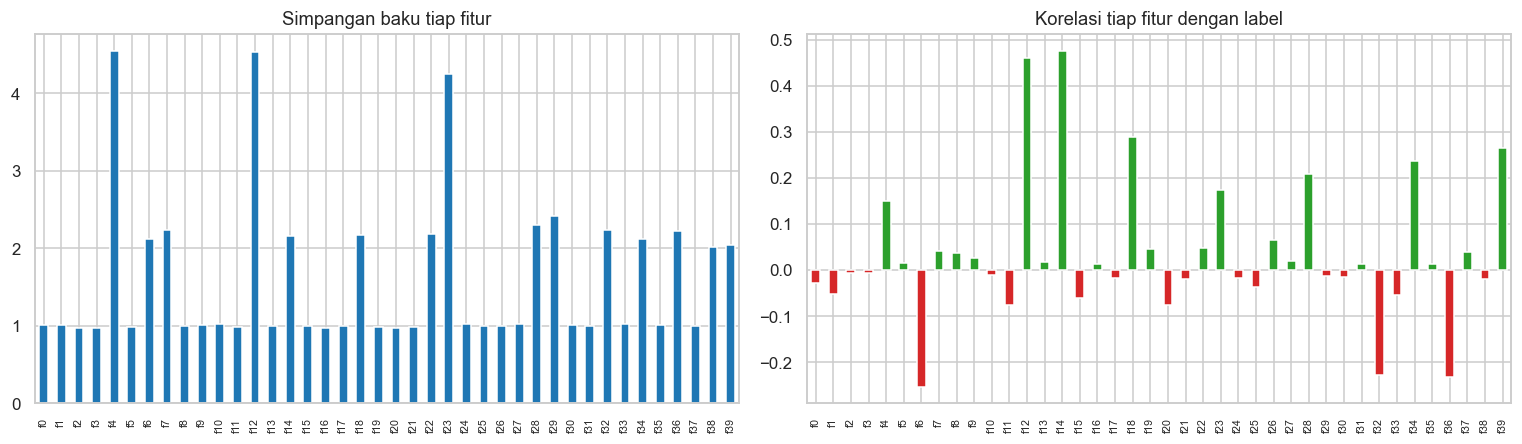

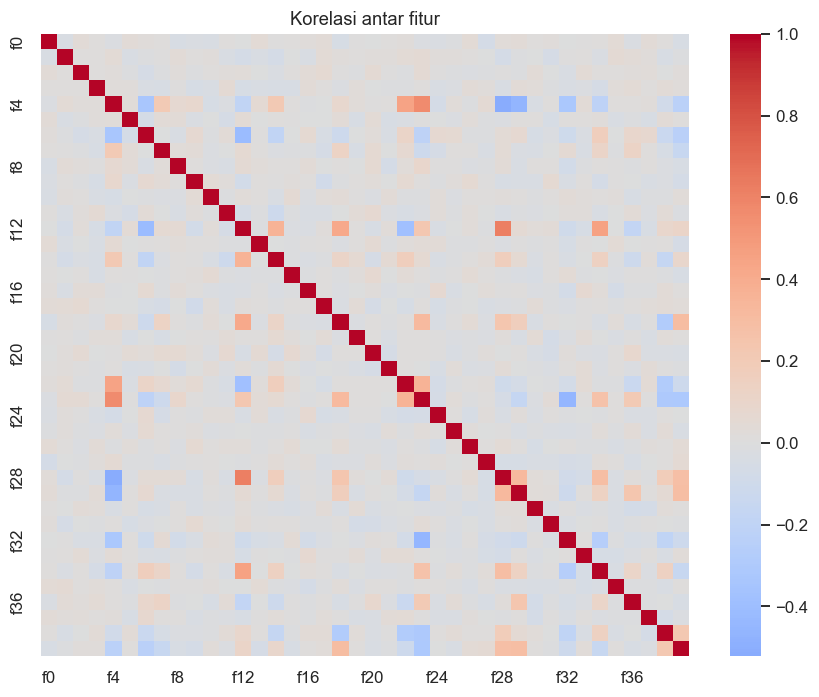

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
X_raw.std().plot(kind="bar", ax=ax[0], color="tab:blue"); ax[0].set_title("Simpangan baku tiap fitur"); ax[0].tick_params(axis="x", labelsize=7)
corr_y = X_raw.apply(lambda c: np.corrcoef(c, y)[0, 1])
corr_y.plot(kind="bar", ax=ax[1], color=np.where(corr_y > 0, "tab:green", "tab:red")); ax[1].set_title("Korelasi tiap fitur dengan label"); ax[1].tick_params(axis="x", labelsize=7)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(X_raw.corr(), cmap="coolwarm", center=0, ax=ax, xticklabels=4, yticklabels=4)
ax.set_title("Korelasi antar fitur"); plt.tight_layout(); plt.show()

**Temuan EDA.** Kelas seimbang (490 vs 510), sehingga accuracy adalah metrik yang wajar. Tidak ada missing value maupun duplikat. Sebagian besar fitur berskala serupa, tetapi beberapa fitur memiliki simpangan baku jauh lebih besar. Hanya sedikit fitur yang berkorelasi linear dengan label, dan beberapa fitur saling berkorelasi kuat (blok merah/biru pada heatmap). Ini menandakan data dibangkitkan dari sumber laten yang sama, dan memotivasi feature engineering berbasis struktur distribusi (bagian b).

## b. Pra-pemrosesan Data
### b.1 Pembagian data: Train / Validation / Test = 60 / 20 / 20 (stratified)
- **Train** → melatih model dan GridSearchCV (5-fold di dalam train).
- **Validation** → memilih set fitur dan strategi encoding.
- **Test** → evaluasi akhir, hanya dipakai sekali di bagian d.

In [4]:
X_tmp, X_te_raw, y_tmp, y_te = train_test_split(X_raw, y, test_size=0.20, stratify=y, random_state=SEED)
X_tr_raw, X_va_raw, y_tr, y_va = train_test_split(X_tmp, y_tmp, test_size=0.25, stratify=y_tmp, random_state=SEED)
print("Train:", X_tr_raw.shape, "| Val:", X_va_raw.shape, "| Test:", X_te_raw.shape)

Train: (600, 40) | Val: (200, 40) | Test: (200, 40)


### b.2 Penanganan missing value dan normalisasi
- **Missing value:** tidak ada (sudah dicek di atas), sehingga imputasi tidak diperlukan.
- **Normalisasi:** Decision Tree, Random Forest, dan XGBoost **tidak sensitif terhadap skala** (pemisahan berdasarkan ambang per fitur). Standardisasi hanya dipakai sebagai langkah sebelum GMM dan KMeans (berbasis jarak/kovarians).

### b.3 Feature Engineering: Gaussian Mixture Model (GMM)
Fitur anonim dan sintetis menyiratkan data dibangkitkan dari campuran beberapa distribusi Gaussian. GMM memodelkan struktur itu secara **unsupervised**, lalu probabilitas posterior tiap komponen dipakai sebagai fitur baru.

- Jumlah komponen dipilih dengan **BIC** (makin kecil makin baik).
- GMM di-fit pada **fitur X train + test Kaggle tanpa label** (10.000 baris). Ini *semi-supervised learning* yang sah: tidak ada label yang dipakai, sehingga tidak ada kebocoran target. Di bawah juga ada **uji kontrol**: GMM di-fit tanpa baris validation/test split, untuk membuktikan bahwa kenaikan skor tidak berasal dari GMM yang "melihat" baris yang dievaluasi.

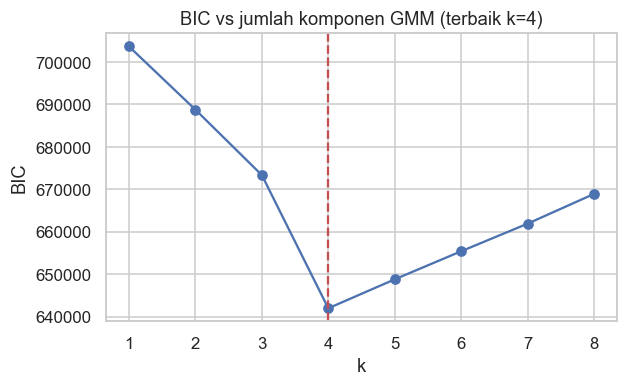

BIC: {1: 703633, 2: 688745, 3: 673335, 4: 641962, 5: 648782, 6: 655394, 7: 661893, 8: 668900}


In [5]:
X_unlab = pd.concat([X_raw, X_test_kaggle], ignore_index=True)       # fitur tanpa label
scaler = StandardScaler().fit(X_unlab)
Z_unlab = scaler.transform(X_unlab)

bic = {}
for k in range(1, 9):
    bic[k] = GaussianMixture(k, covariance_type="full", n_init=3, random_state=SEED).fit(Z_unlab).bic(Z_unlab)
best_k = min(bic, key=bic.get)
plt.figure(figsize=(6, 3.4)); plt.plot(list(bic), list(bic.values()), "o-"); plt.axvline(best_k, ls="--", c="r")
plt.title(f"BIC vs jumlah komponen GMM (terbaik k={best_k})"); plt.xlabel("k"); plt.ylabel("BIC"); plt.show()
print("BIC:", {k: round(v) for k, v in bic.items()})

In [6]:
gmm = GaussianMixture(best_k, covariance_type="full", n_init=3, random_state=SEED).fit(Z_unlab)
KM_K = 16
kmeans = KMeans(KM_K, n_init=10, random_state=SEED).fit(Z_unlab)

def engineer(X):
    # Tambah fitur hasil feature engineering ke fitur mentah.
    Z = scaler.transform(X)
    P = gmm.predict_proba(Z)
    out = X.copy()
    for j in range(best_k): out[f"gmm_p{j}"] = P[:, j]                  # posterior tiap komponen
    out["gmm_loglik"] = gmm.score_samples(Z)                             # seberapa "khas" sampel
    out["gmm_comp"] = P.argmax(axis=1)                                   # kategorikal, < 10 kategori
    out["km_cluster"] = kmeans.predict(Z)                                # kategorikal, >= 10 kategori
    return out

E_tr, E_va, E_te = engineer(X_tr_raw), engineer(X_va_raw), engineer(X_te_raw)
print("Kardinalitas -> gmm_comp:", E_tr["gmm_comp"].nunique(), "| km_cluster:", E_tr["km_cluster"].nunique())
pd.crosstab(E_tr["gmm_comp"], y_tr, rownames=["komponen GMM"], colnames=["label"])

Kardinalitas -> gmm_comp: 4 | km_cluster: 16


label,0,1
komponen GMM,,
0,0,147
1,146,0
2,0,158
3,148,1


Tabel silang di atas memperlihatkan mengapa GMM sangat informatif: setiap komponen GMM hampir seluruhnya berisi **satu label saja**. Struktur laten data ternyata sejalan dengan label.

### b.4 Encoding fitur kategorikal
Dua fitur kategorikal baru dibuat oleh feature engineering:
- `gmm_comp` (**< 10 kategori**) → **One-Hot Encoding**.
- `km_cluster` (16 kategori, **≥ 10 kategori**) → **Target Encoding** dengan *cross-fitting* 5-fold (`TargetEncoder(cv=5)`): nilai encoding untuk tiap baris train dihitung dari fold lain, sehingga label baris itu sendiri tidak bocor ke fiturnya. Sebagai pembanding, `km_cluster` juga di-One-Hot.

In [7]:
NUM_GMM = [f"gmm_p{j}" for j in range(best_k)] + ["gmm_loglik"]
ohe_gmm = OneHotEncoder(sparse_output=False, handle_unknown="ignore").fit(E_tr[["gmm_comp"]])
ohe_km = OneHotEncoder(sparse_output=False, handle_unknown="ignore").fit(E_tr[["km_cluster"]])
te_km = TargetEncoder(target_type="binary", cv=StratifiedKFold(5, shuffle=True, random_state=SEED))
km_te_tr = te_km.fit_transform(E_tr[["km_cluster"]], y_tr)      # cross-fitting -> tanpa leakage
km_te_va, km_te_te = te_km.transform(E_va[["km_cluster"]]), te_km.transform(E_te[["km_cluster"]])

def ohe_frame(enc, E, col):
    return pd.DataFrame(enc.transform(E[[col]]), columns=[f"{col}_{c}" for c in enc.categories_[0]], index=E.index)

def build(E, km_te, mode):
    parts = [E[FEAT_RAW]]
    if mode != "raw":
        parts += [E[NUM_GMM], ohe_frame(ohe_gmm, E, "gmm_comp")]
    if mode == "gmm+km_ohe":
        parts.append(ohe_frame(ohe_km, E, "km_cluster"))
    if mode == "gmm+km_te":
        parts.append(pd.DataFrame(km_te, columns=["km_cluster_te"], index=E.index))
    return pd.concat(parts, axis=1)

SETS = {}
for mode in ["raw", "gmm", "gmm+km_ohe", "gmm+km_te"]:
    SETS[mode] = (build(E_tr, km_te_tr, mode), build(E_va, km_te_va, mode), build(E_te, km_te_te, mode))
    print(f"{mode:<11} -> {SETS[mode][0].shape[1]} fitur")

raw         -> 40 fitur
gmm         -> 49 fitur
gmm+km_ohe  -> 65 fitur
gmm+km_te   -> 50 fitur


In [8]:
# Bandingkan set fitur & strategi encoding pada VALIDATION (RF dan DT baseline)
rows = []
for mode, (A, B, _) in SETS.items():
    for name, m in [("DecisionTree", DecisionTreeClassifier(random_state=SEED)),
                    ("RandomForest", RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1))]:
        m.fit(A, y_tr); rows.append({"set fitur": mode, "model": name, "val accuracy": accuracy_score(y_va, m.predict(B))})
val_tbl = pd.DataFrame(rows).pivot(index="set fitur", columns="model", values="val accuracy").loc[list(SETS)]
display(val_tbl.round(4))

# Uji kontrol leakage: GMM di-fit TANPA baris validation & test split.
def gmm_control(fit_rows, label):
    sc_c = StandardScaler().fit(fit_rows)
    g_c = GaussianMixture(best_k, covariance_type="full", n_init=3, random_state=SEED).fit(sc_c.transform(fit_rows))
    A_c = np.c_[X_tr_raw, g_c.predict_proba(sc_c.transform(X_tr_raw))]
    rf_c = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1).fit(A_c, y_tr)
    out = {}
    for nm, Xe, ye in [("val", X_va_raw, y_va), ("test", X_te_raw, y_te)]:
        out[nm] = accuracy_score(ye, rf_c.predict(np.c_[Xe, g_c.predict_proba(sc_c.transform(Xe))]))
    print(f"{label:<62} n_fit={len(fit_rows):>5} | val={out['val']:.4f} test={out['test']:.4f}")

gmm_control(X_unlab, "(A) GMM utama: semua X train + test Kaggle")
gmm_control(pd.concat([X_tr_raw, X_test_kaggle]), "(B) Kontrol: split train + test Kaggle, TANPA baris val/test")
gmm_control(X_tr_raw, "(C) Hanya split train (600 baris)")

model,DecisionTree,RandomForest
set fitur,,
raw,0.700,0.830
gmm,0.990,0.995
gmm+km_ohe,0.995,0.995
gmm+km_te,0.995,0.995


(A) GMM utama: semua X train + test Kaggle                     n_fit=10000 | val=0.9950 test=0.9900


(B) Kontrol: split train + test Kaggle, TANPA baris val/test   n_fit= 9600 | val=0.9950 test=0.9900


(C) Hanya split train (600 baris)                              n_fit=  600 | val=0.8800 test=0.8750


**Kesimpulan pra-pemrosesan.**

- **Feature engineering GMM adalah faktor penentu.** Akurasi validation naik dari **70,0% → 99,0%** (Decision Tree) dan **83,0% → 99,5%** (Random Forest) hanya dengan menambah fitur GMM. BIC terendah pada **k = 4** komponen, dan tabel silang menunjukkan komponen 0 dan 2 hampir seluruhnya berlabel 1, sedangkan komponen 1 dan 3 berlabel 0 (hanya 1 dari 600 sampel train yang menyimpang).
- **Target Encoding vs One-Hot untuk `km_cluster` (16 kategori):** keduanya memberi akurasi validation yang sama (99,5% untuk DT dan RF), dan keduanya sedikit lebih baik dari set `gmm` saja pada DT (99,0%). Target Encoding dipilih untuk model final karena **jauh lebih ringkas**: 1 kolom dibanding 16 kolom (total 50 vs 65 fitur), sehingga pohon tidak perlu memecah banyak kolom dummy yang jarang bernilai 1. Cross-fitting 5-fold mencegah label sebuah baris ikut menentukan nilai encoding-nya sendiri.
- **Uji kontrol leakage:** GMM yang di-fit tanpa baris validation/test (B) memberi akurasi **identik** dengan GMM utama (A): val 99,5%, test 99,0%. Jadi kenaikan skor tidak berasal dari GMM yang "melihat" baris evaluasi. Sebaliknya, GMM yang hanya di-fit pada 600 baris (C) turun ke 88%, karena GMM kovarians penuh di 40 dimensi memiliki sekitar 3.400 parameter, sehingga 600 sampel terlalu sedikit untuk mengestimasinya. Inilah alasan memanfaatkan 9.000 data test Kaggle **tanpa label**: data tanpa label membantu mempelajari struktur distribusi (semi-supervised learning).

## c. Implementasi Model
Tuning dengan **GridSearchCV** (5-fold stratified, scoring = accuracy sesuai metrik kompetisi) pada split train, untuk dua set fitur: **raw** (40 fitur asli) dan **engineered** (set fitur terbaik dari bagian b). Dengan begitu efek feature engineering terhadap setiap model terlihat jelas.

In [9]:
FINAL_SET = "gmm+km_te"
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
grids = {
    "Decision Tree": (DecisionTreeClassifier(random_state=SEED),
                      {"max_depth": [3, 5, 8, None], "min_samples_split": [2, 10, 20],
                       "min_samples_leaf": [1, 5, 10], "criterion": ["gini", "entropy"]}),
    "Random Forest": (RandomForestClassifier(random_state=SEED, n_jobs=-1),
                      {"n_estimators": [200, 500], "max_depth": [None, 10],
                       "max_features": ["sqrt", 0.3], "criterion": ["gini", "entropy"]}),
    "XGBoost": (XGBClassifier(random_state=SEED, n_jobs=4, verbosity=0, eval_metric="logloss"),
                {"n_estimators": [200, 500], "max_depth": [3, 6], "learning_rate": [0.05, 0.1],
                 "subsample": [0.8, 1.0]}),
}
best_models, tune_rows = {}, []
for set_name, mode in [("raw", "raw"), ("engineered", FINAL_SET)]:
    A = SETS[mode][0]
    for name, (est, grid) in grids.items():
        gs = GridSearchCV(est, grid, cv=cv5, scoring="accuracy", n_jobs=-1).fit(A, y_tr)
        best_models[(name, set_name)] = gs.best_estimator_
        tune_rows.append({"model": name, "set fitur": set_name, "CV accuracy": gs.best_score_, "parameter terbaik": gs.best_params_})
tune_tbl = pd.DataFrame(tune_rows)
pd.set_option("display.max_colwidth", 200)
display(tune_tbl.round(4))

,model,set fitur,CV accuracy,parameter terbaik
0,Decision Tree,raw,0.7867,"{'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2}"
1,Random Forest,raw,0.8750,"{'criterion': 'gini', 'max_depth': None, 'max_features': 0.3, 'n_estimators': 500}"
2,XGBoost,raw,0.8783,"{'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 500, 'subsample': 1.0}"
3,Decision Tree,engineered,0.9983,"{'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}"
4,Random Forest,engineered,0.9983,"{'criterion': 'gini', 'max_depth': None, 'max_features': 'sqrt', 'n_estimators': 200}"
5,XGBoost,engineered,0.9967,"{'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 200, 'subsample': 0.8}"


### Bagging (Random Forest) vs Boosting (XGBoost)
| Aspek | Bagging — Random Forest | Boosting — XGBoost |
|---|---|---|
| Cara membangun | Banyak pohon **paralel & independen**, tiap pohon dari *bootstrap sample* dan subset fitur acak | Pohon dibangun **berurutan**; tiap pohon baru memperbaiki residual/gradien kesalahan pohon sebelumnya |
| Agregasi | *Voting*/rata-rata probabilitas | Jumlah berbobot (dengan *learning rate*) |
| Yang dikurangi | **Varians** (pohon dalam yang overfit dirata-rata) | **Bias** (model lemah diperkuat bertahap) dan juga varians lewat regularisasi |
| Risiko | Jarang overfit dengan menambah pohon | Bisa overfit bila terlalu banyak pohon/learning rate besar, perlu tuning lebih hati-hati |
| Regularisasi | Implisit (acak) | Eksplisit: L1/L2 pada bobot daun, `max_depth`, `subsample`, *shrinkage* |

## d. Evaluasi Model
Evaluasi akhir pada **test split** (200 sampel yang belum pernah dipakai). Metrik kompetisi = accuracy; juga dilaporkan precision, recall, F1, dan ROC-AUC (klasifikasi biner).

In [10]:
eval_rows, probs = [], {}
for (name, set_name), m in best_models.items():
    A_te = SETS["raw" if set_name == "raw" else FINAL_SET][2]
    pred, proba = m.predict(A_te), m.predict_proba(A_te)[:, 1]
    probs[(name, set_name)] = proba
    eval_rows.append({"model": name, "set fitur": set_name, "Accuracy": accuracy_score(y_te, pred),
                      "Precision": precision_score(y_te, pred), "Recall": recall_score(y_te, pred),
                      "F1": f1_score(y_te, pred), "ROC-AUC": roc_auc_score(y_te, proba)})
eval_tbl = pd.DataFrame(eval_rows).set_index(["set fitur", "model"]).sort_index()
display(eval_tbl.round(4))

Accuracy  Precision  Recall      F1  ROC-AUC
set fitur  model                                                      
engineered Decision Tree     0.990     0.9902  0.9902  0.9902   0.9908
           Random Forest     0.990     0.9902  0.9902  0.9902   0.9890
           XGBoost           0.990     0.9902  0.9902  0.9902   0.9915
raw        Decision Tree     0.760     0.7812  0.7353  0.7576   0.7605
           Random Forest     0.875     0.8738  0.8824  0.8780   0.9322
           XGBoost           0.865     0.8571  0.8824  0.8696   0.9344

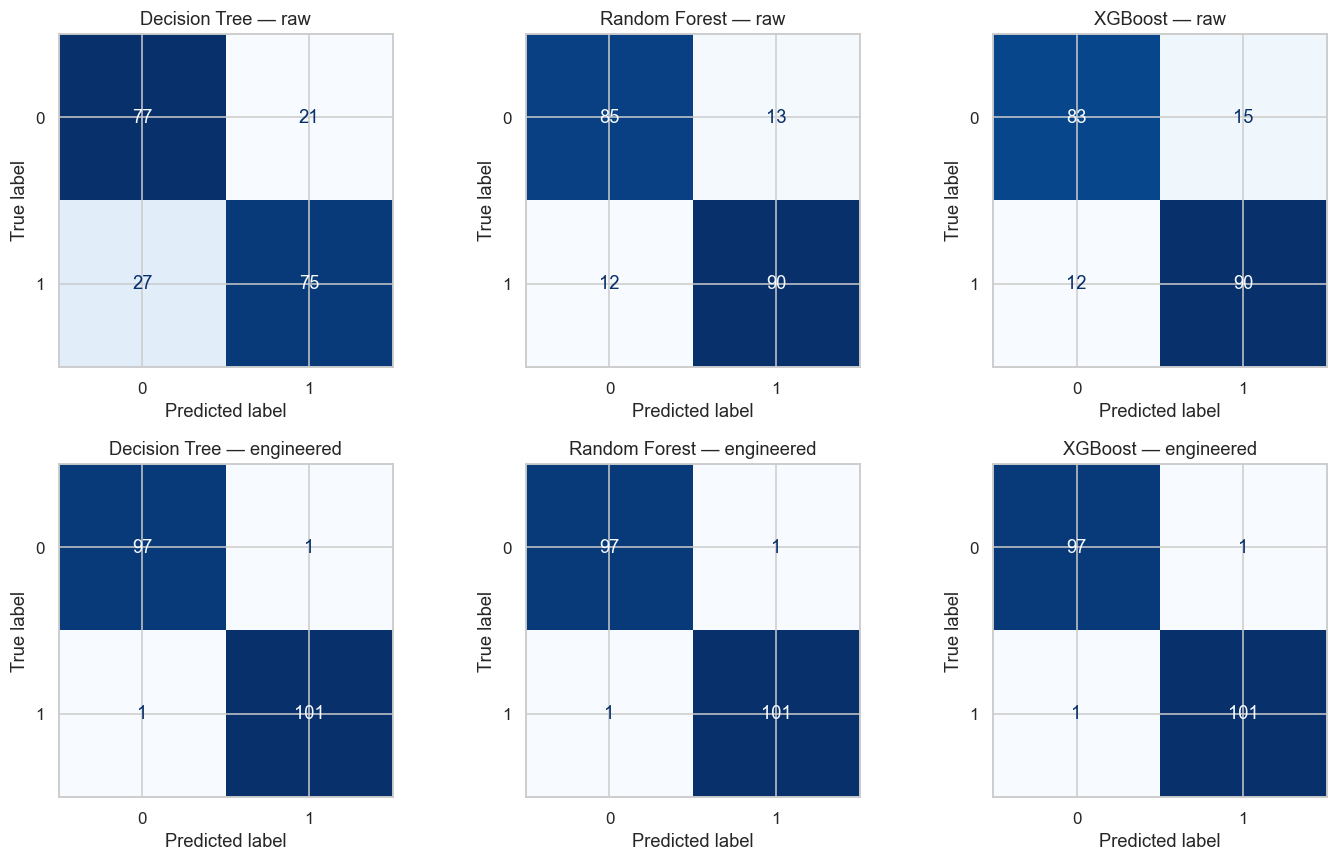

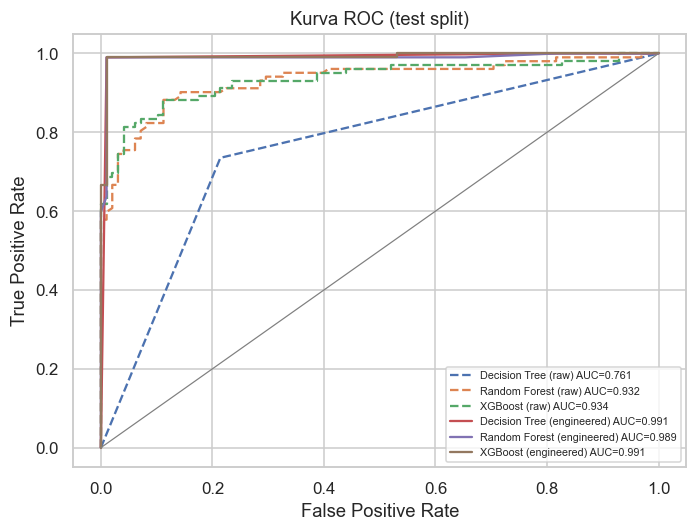

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for r, set_name in enumerate(["raw", "engineered"]):
    for c, name in enumerate(grids):
        A_te = SETS["raw" if set_name == "raw" else FINAL_SET][2]
        ConfusionMatrixDisplay(confusion_matrix(y_te, best_models[(name, set_name)].predict(A_te))).plot(ax=axes[r, c], colorbar=False, cmap="Blues")
        axes[r, c].set_title(f"{name} — {set_name}")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(6.5, 5))
for (name, set_name), p in probs.items():
    fpr, tpr, _ = roc_curve(y_te, p)
    ax.plot(fpr, tpr, ls="-" if set_name == "engineered" else "--", label=f"{name} ({set_name}) AUC={roc_auc_score(y_te, p):.3f}")
ax.plot([0, 1], [0, 1], c="gray", lw=.8)
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate"); ax.legend(fontsize=7)
ax.set_title("Kurva ROC (test split)"); plt.tight_layout(); plt.show()

## e. Visualisasi, Interpretasi & Explainable AI
### e.1 Visualisasi pohon keputusan

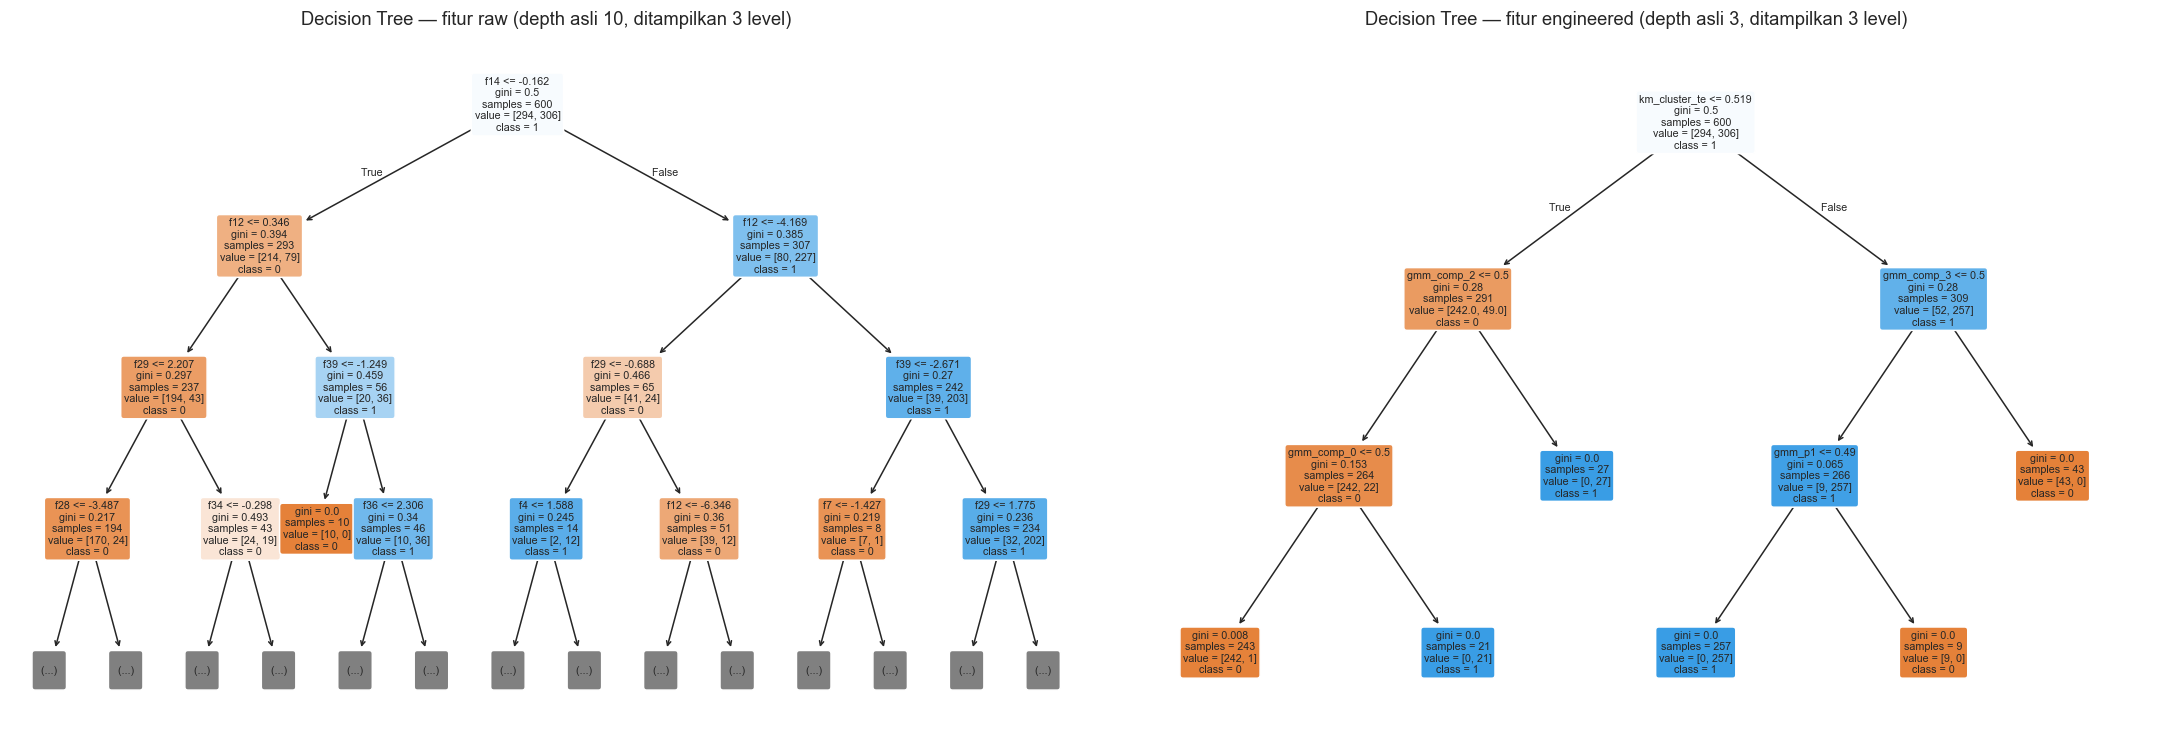

In [12]:
dt_raw, dt_eng = best_models[("Decision Tree", "raw")], best_models[("Decision Tree", "engineered")]
fig, ax = plt.subplots(1, 2, figsize=(20, 7))
plot_tree(dt_raw, max_depth=3, feature_names=list(SETS["raw"][0].columns), class_names=["0", "1"], filled=True, rounded=True, fontsize=7, ax=ax[0])
ax[0].set_title(f"Decision Tree — fitur raw (depth asli {dt_raw.get_depth()}, ditampilkan 3 level)")
plot_tree(dt_eng, max_depth=3, feature_names=list(SETS[FINAL_SET][0].columns), class_names=["0", "1"], filled=True, rounded=True, fontsize=7, ax=ax[1])
ax[1].set_title(f"Decision Tree — fitur engineered (depth asli {dt_eng.get_depth()}, ditampilkan 3 level)")
plt.tight_layout(); plt.show()

### e.2 Feature Importance Random Forest

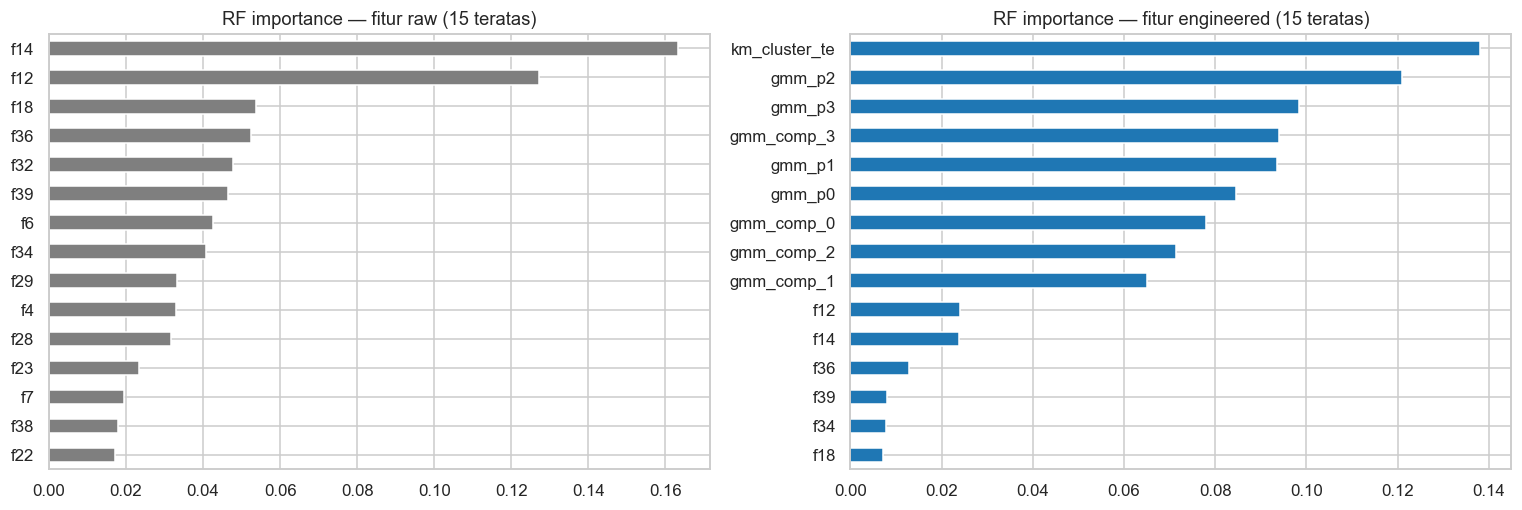

In [13]:
rf_raw, rf_eng = best_models[("Random Forest", "raw")], best_models[("Random Forest", "engineered")]
A_tr_eng, A_va_eng, A_te_eng = SETS[FINAL_SET]
A_tr_raw, A_va_rawset, A_te_rawset = SETS["raw"]
imp_eng = pd.Series(rf_eng.feature_importances_, index=A_tr_eng.columns).sort_values(ascending=False)
imp_raw = pd.Series(rf_raw.feature_importances_, index=A_tr_raw.columns).sort_values(ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
imp_raw.head(15)[::-1].plot(kind="barh", ax=ax[0], color="tab:gray"); ax[0].set_title("RF importance — fitur raw (15 teratas)")
imp_eng.head(15)[::-1].plot(kind="barh", ax=ax[1], color="tab:blue"); ax[1].set_title("RF importance — fitur engineered (15 teratas)")
plt.tight_layout(); plt.show()

### e.3 Explainable AI dengan SHAP
`shap.TreeExplainer` menghitung nilai SHAP **eksak** untuk model pohon. Nilai SHAP fitur $j$ pada sampel $i$ = kontribusi fitur itu mendorong probabilitas kelas 1 naik (positif) atau turun (negatif) relatif terhadap rata-rata prediksi (*base value*). Analisis dilakukan untuk Random Forest engineered (model final) dan Random Forest raw sebagai pembanding.

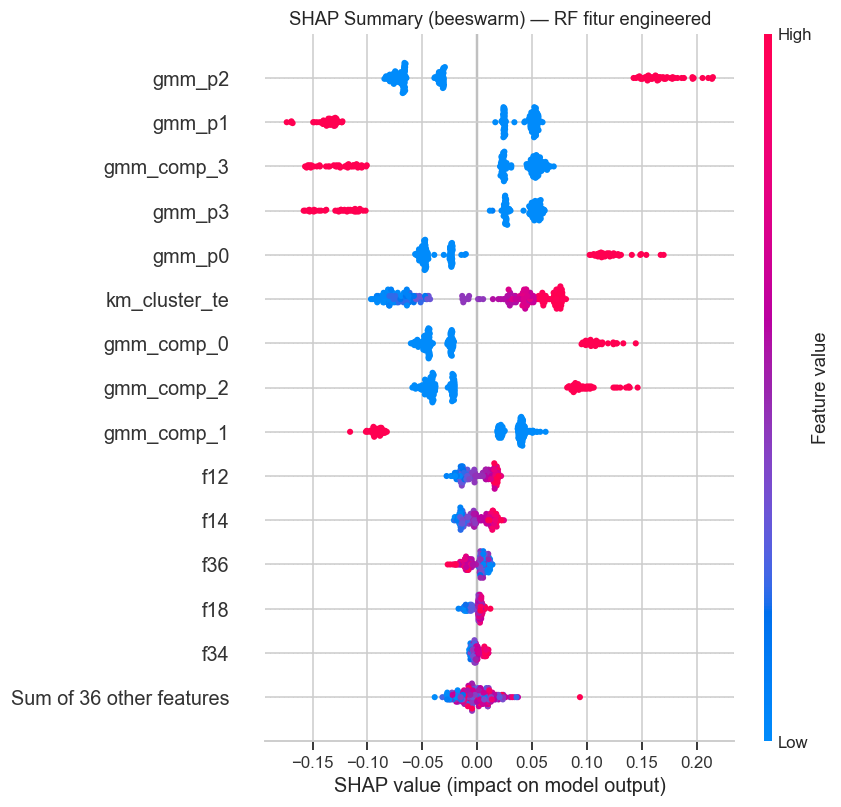

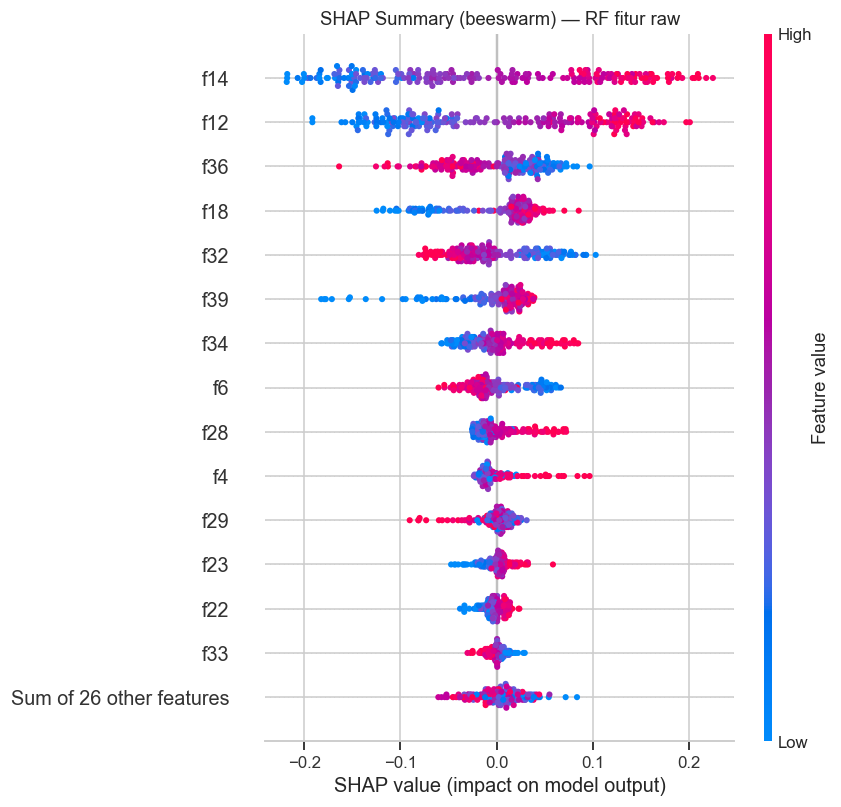

In [14]:
expl_eng = shap.TreeExplainer(rf_eng)
sv_eng = expl_eng(A_te_eng)[:, :, 1]          # kontribusi terhadap kelas 1
expl_raw = shap.TreeExplainer(rf_raw)
sv_raw = expl_raw(A_te_rawset)[:, :, 1]

shap.plots.beeswarm(sv_eng, max_display=15, show=False)
plt.title("SHAP Summary (beeswarm) — RF fitur engineered"); plt.tight_layout(); plt.show()
shap.plots.beeswarm(sv_raw, max_display=15, show=False)
plt.title("SHAP Summary (beeswarm) — RF fitur raw"); plt.tight_layout(); plt.show()

#### SHAP Waterfall: 1 prediksi benar dan 1 prediksi salah
Sampel salah dicari pada test split model final. Bila model final tidak membuat kesalahan sama sekali di test, sampel salah diambil dari model RF raw, dan model yang dijelaskan disebutkan pada judul.

Salah klasifikasi di test -> RF engineered: 2 | RF raw: 25


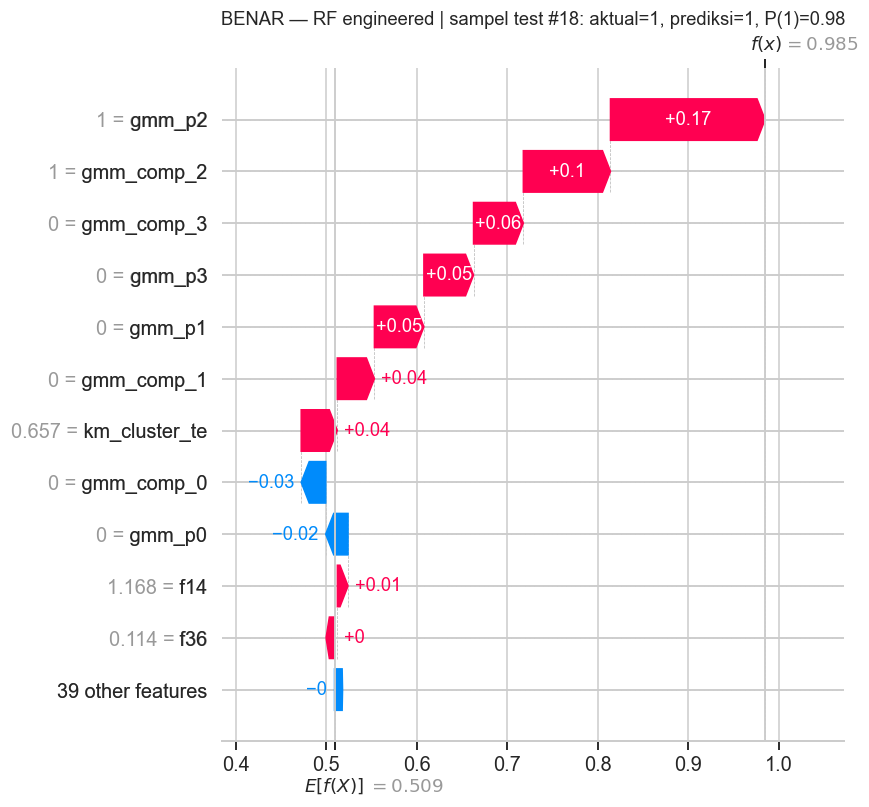

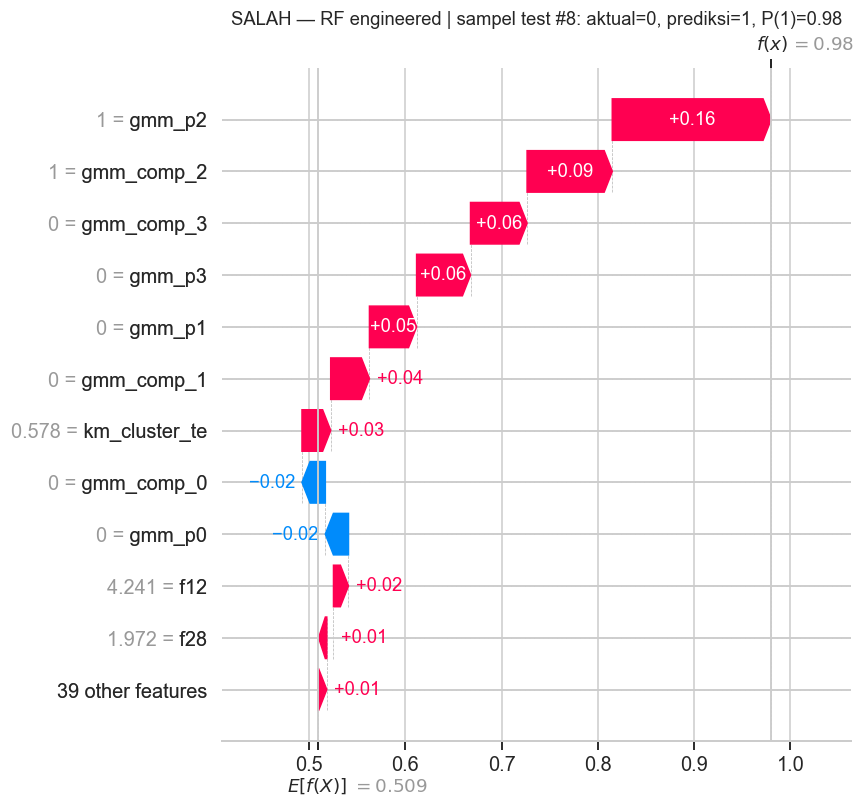

In [15]:
pred_eng = rf_eng.predict(A_te_eng); pred_raw = rf_raw.predict(A_te_rawset)
correct_idx = np.where(pred_eng == y_te)[0]
rng = np.random.default_rng(SEED)
i_ok = int(rng.choice(correct_idx))
wrong_eng = np.where(pred_eng != y_te)[0]
if len(wrong_eng) > 0:
    i_bad, sv_bad, model_bad, pred_bad = int(wrong_eng[0]), sv_eng, "RF engineered", pred_eng
else:
    wrong_raw = np.where(pred_raw != y_te)[0]
    i_bad, sv_bad, model_bad, pred_bad = int(wrong_raw[0]), sv_raw, "RF raw", pred_raw
print(f"Salah klasifikasi di test -> RF engineered: {len(wrong_eng)} | RF raw: {int((pred_raw != y_te).sum())}")

shap.plots.waterfall(sv_eng[i_ok], max_display=12, show=False)
plt.title(f"BENAR — RF engineered | sampel test #{i_ok}: aktual={y_te[i_ok]}, prediksi={pred_eng[i_ok]}, "
          f"P(1)={rf_eng.predict_proba(A_te_eng.iloc[[i_ok]])[0,1]:.2f}"); plt.tight_layout(); plt.show()

A_bad = A_te_eng if model_bad == "RF engineered" else A_te_rawset
m_bad = rf_eng if model_bad == "RF engineered" else rf_raw
shap.plots.waterfall(sv_bad[i_bad], max_display=12, show=False)
plt.title(f"SALAH — {model_bad} | sampel test #{i_bad}: aktual={y_te[i_bad]}, prediksi={pred_bad[i_bad]}, "
          f"P(1)={m_bad.predict_proba(A_bad.iloc[[i_bad]])[0,1]:.2f}"); plt.tight_layout(); plt.show()

# Bila sampel salah berasal dari RF raw, lihat bagaimana model engineered menjelaskan sampel yang sama
if model_bad == "RF raw":
    shap.plots.waterfall(sv_eng[i_bad], max_display=12, show=False)
    plt.title(f"Sampel yang sama #{i_bad} dijelaskan RF engineered: prediksi={pred_eng[i_bad]} (aktual={y_te[i_bad]})"); plt.tight_layout(); plt.show()

#### SHAP vs Feature Importance biasa

In [16]:
def compare(sv, imp, title):
    shap_imp = pd.Series(np.abs(sv.values).mean(axis=0), index=sv.feature_names)
    t = pd.DataFrame({"mean|SHAP|": shap_imp, "RF impurity importance": imp}).fillna(0)
    t["rank SHAP"] = t["mean|SHAP|"].rank(ascending=False).astype(int)
    t["rank impurity"] = t["RF impurity importance"].rank(ascending=False).astype(int)
    rho = t["mean|SHAP|"].corr(t["RF impurity importance"], method="spearman")
    top_s, top_i = set(t.nsmallest(10, "rank SHAP").index), set(t.nsmallest(10, "rank impurity").index)
    print(f"{title}: korelasi Spearman peringkat = {rho:.3f} | irisan 10 teratas = {len(top_s & top_i)}/10")
    return t.sort_values("rank SHAP").head(10)
display(compare(sv_eng, imp_eng, "RF engineered").round(4))
display(compare(sv_raw, imp_raw, "RF raw").round(4))

RF engineered: korelasi Spearman peringkat = 0.959 | irisan 10 teratas = 10/10


,mean|SHAP|,RF impurity importance,rank SHAP,rank impurity
gmm_p2,0.0878,0.1209,1,2
gmm_p1,0.0697,0.0936,2,5
gmm_comp_3,0.0613,0.0939,3,4
gmm_p3,0.0612,0.0985,4,3
gmm_p0,0.0594,0.0847,5,6
km_cluster_te,0.0589,0.1380,6,1
gmm_comp_0,0.0561,0.0780,7,7
gmm_comp_2,0.0536,0.0714,8,8
gmm_comp_1,0.0514,0.0650,9,9
f12,0.0128,0.0240,10,10


RF raw: korelasi Spearman peringkat = 0.941 | irisan 10 teratas = 9/10


,mean|SHAP|,RF impurity importance,rank SHAP,rank impurity
f14,0.1102,0.1634,1,1
f12,0.0939,0.1273,2,2
f36,0.0401,0.0524,3,4
f18,0.0371,0.0538,4,3
f32,0.0371,0.0478,5,5
f39,0.0271,0.0464,6,6
f34,0.0255,0.0408,7,8
f6,0.0231,0.0425,8,7
f28,0.0173,0.0317,9,11
f4,0.0145,0.0329,10,10


### e.4 Interpretasi, kelebihan & kekurangan, kesimpulan

**Hasil tuning dan evaluasi (test split, 200 sampel).**
- **Fitur raw:** Decision Tree 76,0%, Random Forest **87,5%**, XGBoost 86,5% (ROC-AUC RF 0,932, XGB 0,934). Decision Tree terbaik tumbuh sampai kedalaman 10 dan tetap jauh tertinggal, tanda varians tinggi pada satu pohon.
- **Fitur engineered:** ketiga model mencapai **99,0%** (hanya 2 salah dari 200), F1 0,990, ROC-AUC 0,989-0,992. Decision Tree terbaik cukup **kedalaman 3**.
- **Bagging vs boosting:** pada fitur raw, RF dan XGBoost setara (CV 87,5% vs 87,8%; test 87,5% vs 86,5%). Keduanya jauh di atas satu pohon karena sama-sama mengurangi varians/bias pohon tunggal. Pada fitur engineered, perbedaan model hilang: **kualitas fitur jauh lebih menentukan daripada pilihan algoritma.**

**SHAP global (beeswarm).** Pada model final, fitur GMM mendominasi: `gmm_p2` dan `gmm_p0` yang tinggi mendorong prediksi ke **kelas 1**, sedangkan `gmm_p1` dan `gmm_p3` yang tinggi mendorong ke **kelas 0**. Ini sesuai dengan tabel silang komponen GMM. Fitur asli (`f12`, `f14`) hanya memberi koreksi kecil. Pada model raw, `f14` dan `f12` adalah fitur paling berpengaruh, diikuti `f36`, `f18`, `f32`.

**SHAP lokal (waterfall).**
- **Prediksi benar (sampel #18, aktual 1):** berangkat dari base value 0,509, posterior `gmm_p2` = 1 menambah +0,17 dan `gmm_comp_2` +0,10, sedangkan nilai nol pada komponen kelas 0 (`gmm_p1`, `gmm_p3`, `gmm_comp_3`) menambah sekitar +0,05 hingga +0,06 masing-masing. Hasil akhirnya P(1) = 0,985.
- **Prediksi salah (sampel #8, aktual 0, diprediksi 1 dengan P(1) = 0,98):** sampel ini jatuh tepat di **komponen GMM 2**, yang pada data latih seluruhnya berlabel 1. Semua fitur GMM mendorong ke kelas 1 dengan pola yang sama persis seperti sampel benar di atas. Model "yakin tetapi salah": sampel berada di wilayah distribusi kelas 1, sehingga kemungkinan besar ini *noise* label atau wilayah tumpang-tindih kedua kelas. Kesalahan seperti ini tidak dapat diperbaiki dengan tuning, karena tidak ada fitur yang membedakannya dari sampel kelas 1 lainnya.

**SHAP vs Feature Importance (impurity).** Peringkat keduanya sangat mirip (Spearman 0,959 pada model engineered dan 0,941 pada model raw; irisan 10 teratas 10/10 dan 9/10). Perbedaan utamanya: `km_cluster_te` berada di **peringkat 1 menurut impurity** tetapi hanya **peringkat 6 menurut SHAP**. Impurity importance dihitung dari data latih dan cenderung bias ke fitur kontinu yang punya banyak titik potong, serta membagi atau menggandakan kredit di antara fitur yang saling berkorelasi (`gmm_p*` dan `gmm_comp_*` membawa informasi yang sama). SHAP mengukur kontribusi nyata terhadap prediksi pada data test, memberi **arah** pengaruh (naik/turun), dan dapat menjelaskan sampel individual. Feature importance biasa tidak bisa melakukan keduanya.

**Kelebihan & kekurangan pada dataset ini.**

| Metode | Kelebihan | Kekurangan |
|---|---|---|
| Decision Tree | Paling mudah ditafsirkan; dengan fitur engineered cukup 3 level yang bisa dibaca manusia | Pada fitur raw overfit dan tidak stabil (76%) |
| Random Forest | Robust, varians rendah, terbaik pada fitur raw bersama XGBoost; jarang overfit | Sulit ditafsirkan tanpa SHAP; impurity importance bias |
| XGBoost | ROC-AUC tertinggi pada fitur raw; regularisasi eksplisit | Hiperparameter lebih banyak; risiko overfit pada data kecil (600 sampel latih) |
| Feature engineering GMM | Menaikkan akurasi sekitar 12-29 poin dan membuat model sederhana sekalipun hampir sempurna | Butuh banyak data tanpa label (600 sampel tidak cukup); bergantung pada asumsi data campuran Gaussian |

**Kesimpulan.** Kunci dataset ini bukan pemilihan model, melainkan pemahaman struktur data: 40 fitur anonim ternyata dibangkitkan dari 4 komponen Gaussian yang hampir identik dengan label. Dengan memodelkan struktur itu memakai GMM semi-supervised, akurasi naik dari sekitar 87% ke 99%, dan ketiga model menjadi setara. SHAP mengonfirmasi bahwa model final mendasarkan keputusannya pada keanggotaan komponen GMM, dan sisa kesalahannya adalah sampel yang berada di wilayah distribusi kelas lawan.

## f. Submission ke Kaggle (Bonus)
Model final (Random Forest, set fitur engineered, parameter hasil GridSearchCV) dilatih ulang pada **seluruh 1.000 data latih**, lalu memprediksi 9.000 data test Kaggle. Encoder (One-Hot dan Target Encoder) juga di-fit ulang pada seluruh data latih.

In [17]:
E_all, E_kag = engineer(X_raw), engineer(X_test_kaggle)
ohe_gmm = OneHotEncoder(sparse_output=False, handle_unknown="ignore").fit(E_all[["gmm_comp"]])
te_all = TargetEncoder(target_type="binary", cv=StratifiedKFold(5, shuffle=True, random_state=SEED))
A_all = build(E_all, te_all.fit_transform(E_all[["km_cluster"]], y), FINAL_SET)
A_kag = build(E_kag, te_all.transform(E_kag[["km_cluster"]]), FINAL_SET)
final_rf = RandomForestClassifier(**rf_eng.get_params()).fit(A_all, y)
print("CV accuracy 5-fold model final pada seluruh data latih: %.4f" % cross_val_score(RandomForestClassifier(**rf_eng.get_params()), A_all, y, cv=cv5).mean())
sub = pd.DataFrame({"Id": np.arange(1, len(A_kag) + 1), "Solution": final_rf.predict(A_kag)})
sub.to_csv("submission_london.csv", index=False)
print(sub.shape, "| distribusi prediksi:", sub["Solution"].value_counts().to_dict())
sub.head()

CV accuracy 5-fold model final pada seluruh data latih: 0.9960
(9000, 2) | distribusi prediksi: {0: 4507, 1: 4493}


,Id,Solution
0,1,1
1,2,0
2,3,1
3,4,0
4,5,0


File `submission_london.csv` siap diunggah ke halaman kompetisi. **Strategi peningkatan skor:** (1) feature engineering GMM semi-supervised yang memanfaatkan 9.000 data test tanpa label untuk mempelajari struktur distribusi, (2) pemilihan jumlah komponen dengan BIC, (3) tuning hiperparameter dengan GridSearchCV, (4) validasi berlapis (CV + validation + test) agar skor tidak bias karena kebetulan pembagian data.

## Referensi

| No | Sumber / Tool | Tujuan Penggunaan | Link / Keterangan |
|----|---------------|-------------------|-------------------|
| 1 | Kaggle — Data Science London + Scikit-learn | Sumber dataset & aturan kompetisi | https://www.kaggle.com/competitions/data-science-london-scikit-learn |
| 2 | Scikit-Learn documentation | GaussianMixture, TargetEncoder, GridSearchCV, plot_tree | https://scikit-learn.org |
| 3 | SHAP documentation (Lundberg & Lee, 2017) | TreeExplainer, beeswarm & waterfall plot | https://shap.readthedocs.io |
| 4 | XGBoost documentation | XGBClassifier | https://xgboost.readthedocs.io |